# Рубежный контроль №1

**Тема:** Технологии разведочного анализа и обработки данных

**Вариант:** 9 — задача №2, набор данных №1 (Iris (sklearn.datasets.load_iris))

**Студент:** Зеленцов Антон  
**Группа:** ИУ5-XXБ  
**Дата:** 11.11.2026

---

Ссылка на задание: https://github.com/ugapanyuk/courses_current/wiki/TMO_RK_1


## 1. Постановка задачи

Ссылка на задание: https://github.com/ugapanyuk/courses_current/wiki/TMO_RK_1

Тема: технологии разведочного анализа и обработки данных.

Вариант №9: задача №2, набор данных №1 — Iris (sklearn.datasets.load_iris).

#### Постановка задачи

Для заданного набора данных провести обработку пропусков в данных для одного категориального и одного количественного признака. Какие способы обработки пропусков в данных для категориальных и количественных признаков Вы использовали? Какие признаки Вы будете использовать для дальнейшего построения моделей машинного обучения и почему?

#### Подготовка набора данных

В наборе Iris 150 наблюдений, 4 количественных признака (sepal_length, sepal_width, petal_length, petal_width) и целевая переменная species с тремя сбалансированными классами (setosa, versicolor, virginica — по 50 объектов). Категориальных признаков и пропусков в исходных данных нет, поэтому в соответствии с примечанием к заданию они созданы искусственно:

- sepal_width_cat — категориальный признак, полученный разбиением количественного sepal_width на три равные по числу наблюдений группы (terciles): «узкая», «средняя», «широкая»;
- пропуски внесены в sepal_width_cat (18 значений, 12 % наблюдений) и в petal_length (15 значений, 10 % наблюдений) с фиксированным зерном генератора случайных чисел (random_state = 42), чтобы результат был полностью воспроизводим.
- Так как пропуски созданы искусственно, их истинные значения известны. Это позволило не только применить способы обработки, но и объективно сравнить их по метрикам MAE и RMSE (для количественного признака) и по доле верно восстановленных категорий (для категориального признака).

## 2. Подготовка окружения

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.datasets import load_iris
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Кириллица в подписях графиков
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="DejaVu Sans")

RANDOM_STATE = 42
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)


def save_fig(fig, name):
    """Сохраняет рисунок в папку figures — эти же файлы вставлены в отчет."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("scikit-learn:", __import__("sklearn").__version__, "| seaborn:", sns.__version__)


pandas: 2.2.3 | numpy: 2.1.1
scikit-learn: 1.9.0 | seaborn: 0.13.2


## 3. Загрузка данных и создание пропусков

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "target"]
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

# В Iris нет категориальных признаков, поэтому создаем его из количественного sepal_width:
# разбиваем значения на три равные по числу наблюдений группы (terciles)
df["sepal_width_cat"] = pd.qcut(df["sepal_width"], q=3,
                                labels=["узкая", "средняя", "широкая"]).astype(object)

# В Iris нет пропусков, поэтому вносим их искусственно (примечание к заданию)
rng = np.random.default_rng(RANDOM_STATE)
idx_cat = rng.choice(df.index, size=18, replace=False)                      # 12 % категориального
idx_num = rng.choice(df.index.difference(idx_cat), size=15, replace=False)  # 10 % количественного

df_clean = df.copy()          # эталон без пропусков: истинные значения известны
df_miss = df.copy()           # набор с пропусками
df_miss.loc[idx_cat, "sepal_width_cat"] = np.nan
df_miss.loc[idx_num, "petal_length"] = np.nan

df.to_csv(DATA_DIR / "iris.csv", index=False)
df_miss.to_csv(DATA_DIR / "iris_missing.csv", index=False)

num_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

print("Размер набора:", df_miss.shape)
print("\nПропуски по столбцам:")
print(df_miss.isna().sum()[df_miss.isna().sum() > 0].to_string())
print("\nДоля пропусков:")
print((df_miss.isna().mean()[df_miss.isna().mean() > 0] * 100).round(1).to_string(), "%")
print("\nЧисло объектов по видам:", df_miss["species"].value_counts().sort_index().to_dict())
display(df_miss.head())
display(df_miss[num_cols].describe().round(3))


Размер набора: (150, 7)

Пропуски по столбцам:
petal_length       15
sepal_width_cat    18

Доля пропусков:
petal_length       10.0
sepal_width_cat    12.0 %

Число объектов по видам: {np.str_('setosa'): 50, np.str_('versicolor'): 50, np.str_('virginica'): 50}


,sepal_length,sepal_width,petal_length,petal_width,target,species,sepal_width_cat
0,5.1,3.5,1.4,0.2,0,setosa,широкая
1,4.9,3.0,1.4,0.2,0,setosa,средняя
2,4.7,3.2,1.3,0.2,0,setosa,средняя
3,4.6,3.1,1.5,0.2,0,setosa,средняя
4,5.0,3.6,1.4,0.2,0,setosa,широкая


,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,135.000,150.000
mean,5.843,3.057,3.749,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.400,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


## 4. Первичный анализ пропусков

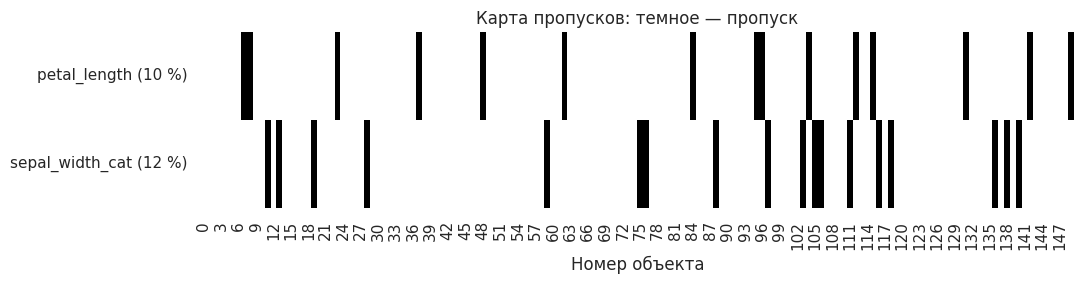

In [3]:
fig, ax = plt.subplots(figsize=(11, 3))
sns.heatmap(df_miss[["petal_length", "sepal_width_cat"]].isna().T, cbar=False,
            cmap="Greys", ax=ax)
ax.set_title("Карта пропусков: темное — пропуск")
ax.set_xlabel("Номер объекта")
ax.set_yticklabels(["petal_length (10 %)", "sepal_width_cat (12 %)"], rotation=0)
plt.tight_layout()
save_fig(fig, "fig01_missing_map.png")
plt.show()


Корреляция Пирсона (по полному набору без пропусков):


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.118,0.872,0.818
sepal_width,-0.118,1.000,-0.428,-0.366
petal_length,0.872,-0.428,1.000,0.963
petal_width,0.818,-0.366,0.963,1.000


Связь petal_length с остальными признаками:
sepal_length    0.872
sepal_width    -0.428
petal_width     0.963


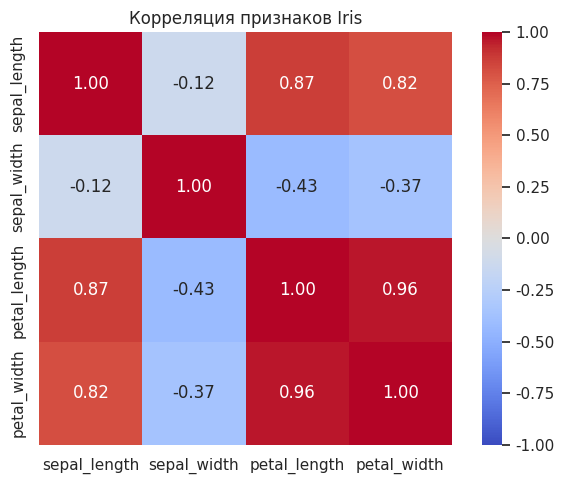

In [4]:
# Проверяем, есть ли корреляции, на которых можно построить модельное заполнение
corr = df_clean[num_cols].corr()
print("Корреляция Пирсона (по полному набору без пропусков):")
display(corr.round(3))
print("Связь petal_length с остальными признаками:")
print(corr["petal_length"].drop("petal_length").round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, ax=ax)
ax.set_title("Корреляция признаков Iris")
plt.tight_layout()
save_fig(fig, "fig02_corr.png")
plt.show()


## 5. Обработка пропусков количественного признака `petal_length`

In [5]:
# ---------- Количественный признак petal_length: 15 пропусков (10 %) ----------
true_num = df_clean.loc[idx_num, "petal_length"]   # истинные значения (пропуски внесены нами)

# Способ 1: удаление строк
rows_dropped = df_miss.dropna(subset=["petal_length"])
print(f"Удаление строк: осталось {len(rows_dropped)} из {len(df_miss)} наблюдений "
      f"(потеряно {len(df_miss) - len(rows_dropped)} строк, "
      f"{100 * (1 - len(rows_dropped) / len(df_miss)):.1f} %)")

# Способы 2-4: заполнение средним, медианой и методом k ближайших соседей
filled = {
    "Среднее": pd.Series(
        SimpleImputer(strategy="mean").fit_transform(df_miss[["petal_length"]])[:, 0],
        index=df_miss.index),
    "Медиана": pd.Series(
        SimpleImputer(strategy="median").fit_transform(df_miss[["petal_length"]])[:, 0],
        index=df_miss.index),
    "KNN (k=5)": pd.Series(
        KNNImputer(n_neighbors=5).fit_transform(df_miss[num_cols])[:, num_cols.index("petal_length")],
        index=df_miss.index),
}

rows = []
for name, series in filled.items():
    pred = series.loc[idx_num]
    rows.append({"Способ заполнения": name,
                 "MAE, см": mean_absolute_error(true_num, pred),
                 "RMSE, см": np.sqrt(mean_squared_error(true_num, pred))})
impute_metrics = pd.DataFrame(rows).set_index("Способ заполнения").round(3)
print("\nКачество восстановления petal_length (сравнение с истинными значениями):")
display(impute_metrics)
print("Лучший способ по MAE:", impute_metrics["MAE, см"].idxmin())


Удаление строк: осталось 135 из 150 наблюдений (потеряно 15 строк, 10.0 %)

Качество восстановления petal_length (сравнение с истинными значениями):


,"MAE, см","RMSE, см"
Способ заполнения,,
Среднее,1.590,1.765
Медиана,1.480,1.850
KNN (k=5),0.188,0.240


Лучший способ по MAE: KNN (k=5)


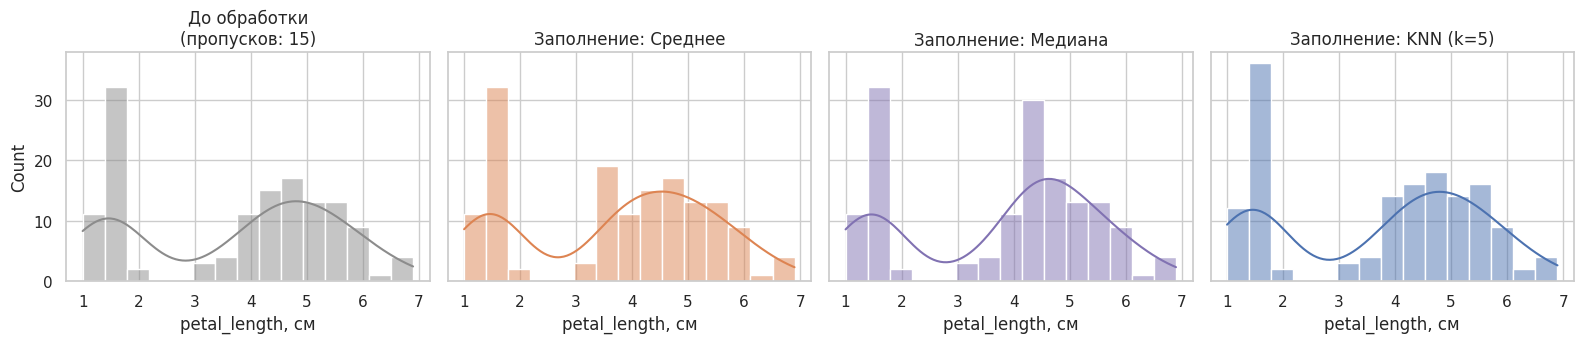

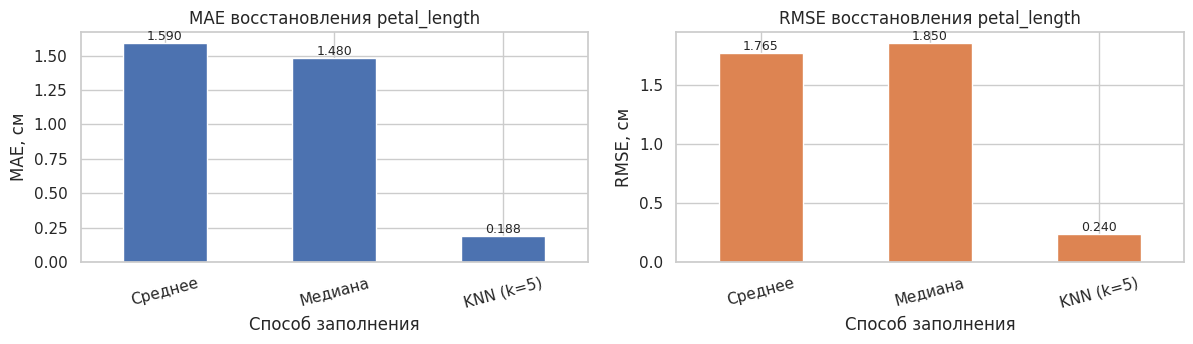

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
sns.histplot(df_miss["petal_length"].dropna(), bins=15, kde=True, ax=axes[0], color="#8c8c8c")
axes[0].set_title(f"До обработки\n(пропусков: {int(df_miss['petal_length'].isna().sum())})")
for ax, name, color in zip(axes[1:], ["Среднее", "Медиана", "KNN (k=5)"],
                           ["#DD8452", "#8172B2", "#4C72B0"]):
    sns.histplot(filled[name], bins=15, kde=True, ax=ax, color=color)
    ax.set_title(f"Заполнение: {name}")
for ax in axes:
    ax.set_xlabel("petal_length, см")
plt.tight_layout()
save_fig(fig, "fig03_num_impute_hist.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, metric, color in zip(axes, ["MAE, см", "RMSE, см"], ["#4C72B0", "#DD8452"]):
    impute_metrics[metric].plot(kind="bar", ax=ax, color=color, rot=15)
    ax.set_title(f"{metric.split(',')[0]} восстановления petal_length")
    ax.set_ylabel(metric)
    for patch in ax.patches:
        ax.annotate(f"{patch.get_height():.3f}",
                    (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
save_fig(fig, "fig04_num_impute_metrics.png")
plt.show()


## 6. Обработка пропусков категориального признака `sepal_width_cat`

In [7]:
# ---------- Категориальный признак sepal_width_cat: 18 пропусков (12 %) ----------
mode_value = df_miss["sepal_width_cat"].mode()[0]

# Способ 1: заполнение модой
cat_mode = df_miss["sepal_width_cat"].fillna(mode_value)
# Способ 2: замена отдельной категорией "неизвестно"
cat_unknown = df_miss["sepal_width_cat"].fillna("неизвестно")
# Для сравнения: удаление строк
cat_dropped = df_miss["sepal_width_cat"].dropna()

true_cat = df_clean.loc[idx_cat, "sepal_width_cat"]
mode_accuracy = (cat_mode.loc[idx_cat].astype(str).values == true_cat.astype(str).values).mean()
print(f"Мода категориального признака: '{mode_value}' ({int((df_miss['sepal_width_cat'] == mode_value).sum())} наблюдений)")
print(f"Доля верно восстановленных категорий способом 'мода': {mode_accuracy:.1%}")
print(f"Удаление строк: осталось {len(cat_dropped)} из {len(df_miss)} наблюдений")

cat_compare = pd.DataFrame({
    "Исходные (без пропусков)": df_miss["sepal_width_cat"].value_counts(normalize=True),
    "Заполнение модой": cat_mode.value_counts(normalize=True),
    "Категория 'неизвестно'": cat_unknown.value_counts(normalize=True),
}).fillna(0).round(3)
print("\nРаспределение категорий (доли):")
display(cat_compare)


Мода категориального признака: 'узкая' (50 наблюдений)
Доля верно восстановленных категорий способом 'мода': 38.9%
Удаление строк: осталось 132 из 150 наблюдений

Распределение категорий (доли):


,Исходные (без пропусков),Заполнение модой,Категория 'неизвестно'
sepal_width_cat,,,
неизвестно,0.000,0.000,0.120
средняя,0.326,0.287,0.287
узкая,0.379,0.453,0.333
широкая,0.295,0.260,0.260


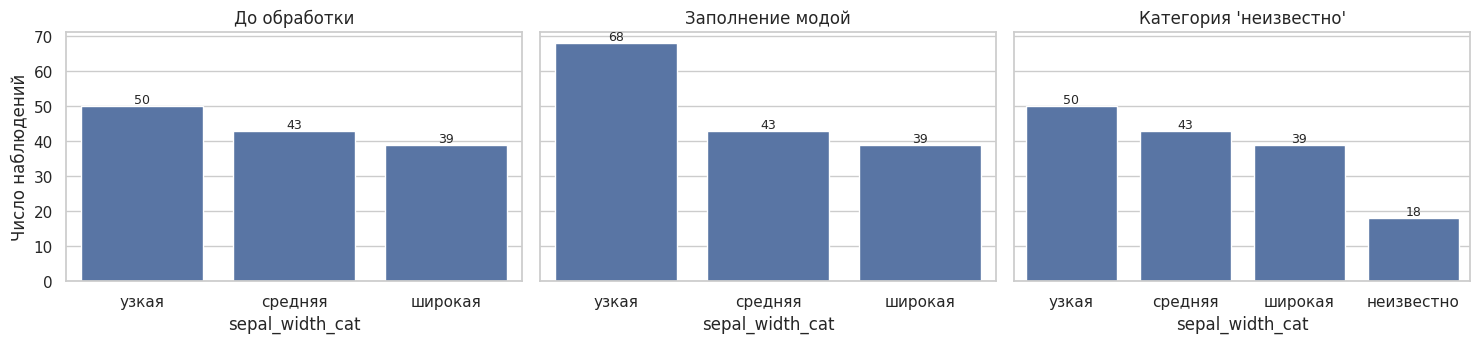

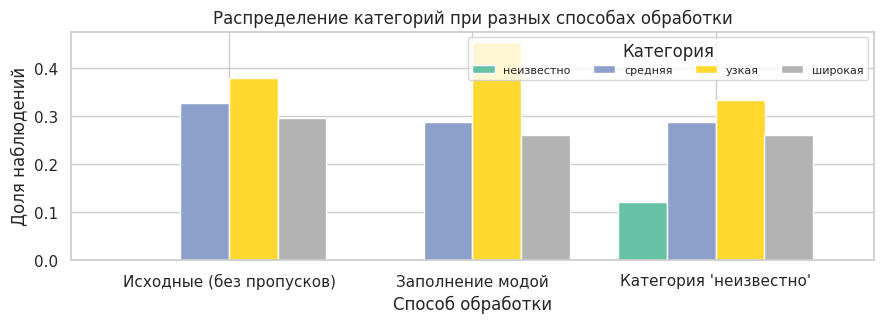

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
order = ["узкая", "средняя", "широкая", "неизвестно"]
for ax, title, series in zip(
        axes,
        ["До обработки", "Заполнение модой", "Категория 'неизвестно'"],
        [df_miss["sepal_width_cat"], cat_mode, cat_unknown]):
    present = [o for o in order if o in set(series)]
    sns.countplot(x=series, order=present, ax=ax, color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("sepal_width_cat")
    ax.set_ylabel("Число наблюдений")
    for patch in ax.patches:
        ax.annotate(f"{int(patch.get_height())}",
                    (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
save_fig(fig, "fig05_cat_impute.png")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
cat_compare.T.plot(kind="bar", rot=0, ax=ax, colormap="Set2", width=0.8)
ax.set_title("Распределение категорий при разных способах обработки")
ax.set_ylabel("Доля наблюдений")
ax.set_xlabel("Способ обработки")
ax.legend(title="Категория", ncol=4, fontsize=8)
plt.tight_layout()
save_fig(fig, "fig06_cat_compare.png")
plt.show()


## 7. Итоговый набор данных

In [9]:
# ---------- Итоговый набор: KNN для количественного, мода для категориального ----------
df_prepared = df_miss.copy()
df_prepared["petal_length"] = filled["KNN (k=5)"]
df_prepared["sepal_width_cat"] = cat_mode

print("Размер итогового набора:", df_prepared.shape)
print("Пропусков после обработки:", int(df_prepared.isna().sum().sum()))

feature_cols = num_cols + ["sepal_width_cat"]
final_df = df_prepared[feature_cols + ["species"]].copy()
final_df.to_csv(DATA_DIR / "iris_prepared.csv", index=False)

print("\nТипы данных:")
print(final_df.dtypes.to_string())
display(final_df.head())

# Проверяем, что заполнение не исказило распределения
check = pd.DataFrame({
    "Исходный (без пропусков)": df_clean[num_cols].agg(["mean", "std", "median"]).stack(),
    "После обработки": df_prepared[num_cols].agg(["mean", "std", "median"]).stack(),
}).unstack().round(3)
print("\nСравнение статистик до и после обработки пропусков:")
display(check)


Размер итогового набора: (150, 7)
Пропусков после обработки: 0

Типы данных:
sepal_length       float64
sepal_width        float64
petal_length       float64
petal_width        float64
sepal_width_cat     object
species             object


,sepal_length,sepal_width,petal_length,petal_width,sepal_width_cat,species
0,5.1,3.5,1.4,0.2,широкая,setosa
1,4.9,3.0,1.4,0.2,средняя,setosa
2,4.7,3.2,1.3,0.2,средняя,setosa
3,4.6,3.1,1.5,0.2,средняя,setosa
4,5.0,3.6,1.4,0.2,широкая,setosa



Сравнение статистик до и после обработки пропусков:


Исходный (без пропусков)                                       \
                   sepal_length sepal_width petal_length petal_width   
mean                      5.843       3.057        3.758       1.199   
std                       0.828       0.436        1.765       0.762   
median                    5.800       3.000        4.350       1.300   

       После обработки                                       
          sepal_length sepal_width petal_length petal_width  
mean             5.843       3.057        3.746       1.199  
std              0.828       0.436        1.762       0.762  
median           5.800       3.000        4.300       1.300

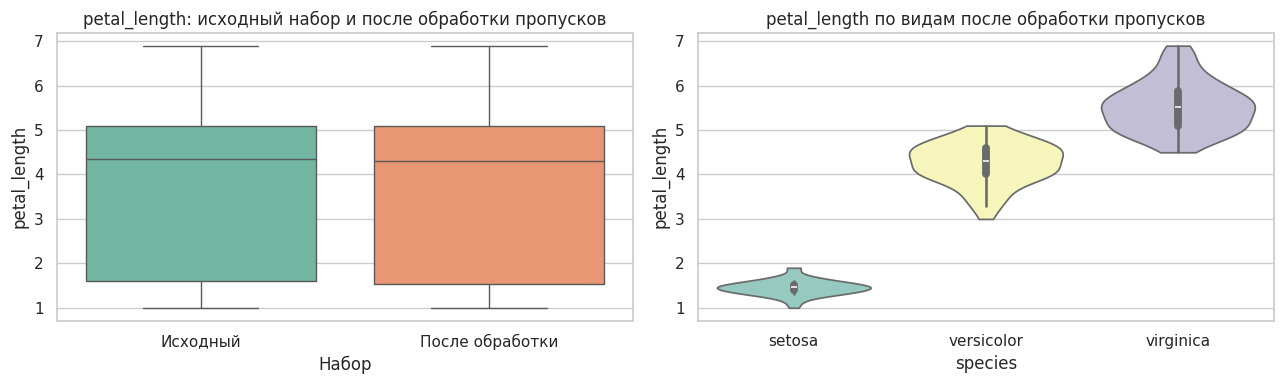

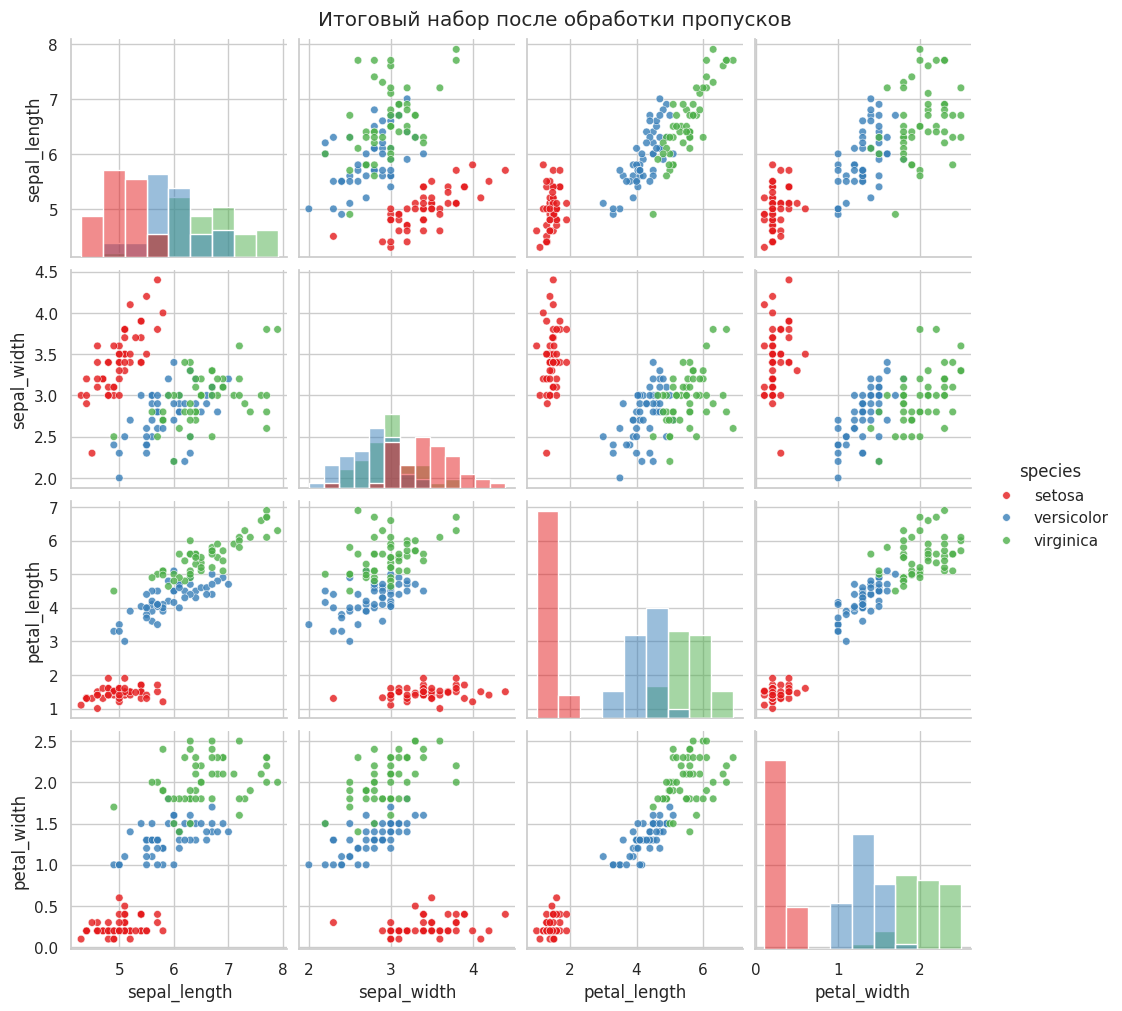

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=pd.concat([df_clean[["petal_length"]].assign(Набор="Исходный"),
                            df_prepared[["petal_length"]].assign(Набор="После обработки")]),
            x="Набор", y="petal_length", ax=axes[0], palette="Set2")
axes[0].set_title("petal_length: исходный набор и после обработки пропусков")
sns.violinplot(data=final_df, x="species", y="petal_length", palette="Set3", ax=axes[1], cut=0)
axes[1].set_title("petal_length по видам после обработки пропусков")
plt.tight_layout()
save_fig(fig, "fig07_final_check.png")
plt.show()

pair = sns.pairplot(final_df, vars=num_cols, hue="species", palette="Set1",
                    diag_kind="hist", plot_kws={"s": 30, "alpha": 0.8})
pair.figure.suptitle("Итоговый набор после обработки пропусков", y=1.01)
save_fig(pair.figure, "fig08_final_pairplot.png")
plt.show()


## 8. Обоснование выбора признаков для модели

Корреляционное отношение eta (связь признака с видом):


,eta
petal_length,0.940
petal_width,0.929
sepal_length,0.619
sepal_width,0.401


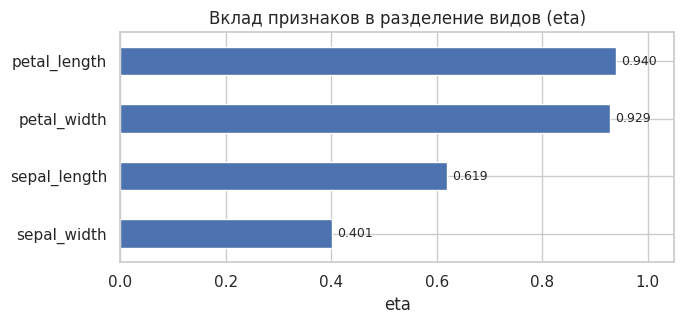


Мультиколлинеарность (|r| > 0,8):
  sepal_length — petal_length: r = 0.872
  sepal_length — petal_width: r = 0.818
  petal_length — petal_width: r = 0.963


In [11]:
# ---------- Обоснование выбора признаков для модели ----------
def eta_squared(values, groups):
    """Корреляционное отношение eta: сила связи количественного признака с классом."""
    values, groups = pd.Series(values), pd.Series(groups)
    grand_mean = values.mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for _, g in values.groupby(groups))
    ss_total = ((values - grand_mean) ** 2).sum()
    return ss_between / ss_total


eta = pd.Series({c: eta_squared(final_df[c], final_df["species"]) for c in num_cols}).sort_values(ascending=False)
print("Корреляционное отношение eta (связь признака с видом):")
display(eta.round(3).to_frame("eta"))

fig, ax = plt.subplots(figsize=(7, 3.4))
eta.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Вклад признаков в разделение видов (eta)")
ax.set_xlabel("eta")
for i, v in enumerate(eta.sort_values()):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, 1.05)
plt.tight_layout()
save_fig(fig, "fig09_eta.png")
plt.show()

print("\nМультиколлинеарность (|r| > 0,8):")
for i, a in enumerate(num_cols):
    for b in num_cols[i + 1:]:
        if abs(corr.loc[a, b]) > 0.8:
            print(f"  {a} — {b}: r = {corr.loc[a, b]:.3f}")


## 9. Ответы на вопросы задания

### Способы обработки пропусков

#### Способы обработки пропусков количественного признака petal_length

- Удаление строк (dropna) — baseline: строки с пропуском просто исключаются из набора. Метод не вносит искажений, но уменьшает выборку: по признаку petal_length теряется 15 строк (10 %), а если удалять все строки, где есть пропуск хотя бы в одном признаке, — 33 строки (22 %). Кроме того, удаление может сместить оценки, если пропуски не вполне случайны.
- Заполнение средним (mean imputation) — пропуск заменяется средним по столбцу. Просто и быстро, но сильно искажает распределение: MAE ≈ 1,59 см, RMSE ≈ 1,76 см. Причина в том, что petal_length в Iris бимодален (setosa ≈ 1,5 см, остальные виды ≈ 4,3–5,1 см), а глобальное среднее ≈ 3,75 см попадает в «провал» между модами и не подходит ни одному классу.
- Заполнение медианой (median imputation) — пропуск заменяется медианой. Метод устойчив к выбросам и асимметрии, MAE ≈ 1,48 см, RMSE ≈ 1,85 см. Для бимодального распределения медиана также попадает в область между модами, поэтому выигрыш по сравнению со средним незначителен.
- Заполнение методом k ближайших соседей (KNNImputer, k = 5) — значение признака восстанавливается как среднее значение petal_length у 5 наиболее похожих объектов по остальным признакам. Метод дал MAE ≈ 0,19 см и RMSE ≈ 0,24 см, то есть ошибка меньше на порядок: он использует сильную корреляцию petal_length с petal_width (r ≈ 0,96) и sepal_length (r ≈ 0,88), поэтому «узнаёт», к какому классу относится объект, и подставляет значение из нужной моды.

#### Способы обработки пропусков категориального признака sepal_width_cat

- Заполнение модой (most frequent) — пропуск заменяется наиболее частой категорией («узкая», 50 наблюдений). Метод сохраняет размер выборки и не создаёт новых уровней признака. Доля верно восстановленных категорий — 38,9 %, то есть примерно на уровне случайного угадывания (1/3), что ожидаемо: между шириной чашелистика и группами нет сильной связи, а мода одна для всех объектов.
- Замена отдельной категорией «неизвестно» (missing as a category) — пропуск становится самостоятельным уровнем признака. Метод сохраняет информацию о самом факте отсутствия значения и корректен, если пропуски неслучайны (MNAR). Плата — новый уровень признака и «размывание» исходного распределения категорий.
- Дополнительно рассмотрен вариант удаления строк — он применён только как точка сравнения, поскольку в задаче требуется именно обработка (заполнение) пропусков.

#### Почему выбраны именно эти способы

- Пропуски в наборе носят характер MCAR (missing completely at random): они внесены случайно и не связаны ни с объектом, ни со значением признака. При MCAR заполнение не смещает оценки генеральной совокупности, а удаление строк уменьшает выборку без выигрыша в качестве.
- Для количественного признака основным выбран KNN-метод, потому что признаки набора сильно коррелируют и значение petal_length хорошо предсказывается по соседям; это подтверждено метриками. Медиана оставлена как «быстрый» резервный вариант, среднее — как учебный baseline, показывающий, почему для бимодальных распределений оно непригодно.
- Для категориального признака основным выбран вариант с модой: он не увеличивает размерность и не вводит новый уровень. Вариант «неизвестно» оставлен как альтернатива, которую следует применять, если бы пропуски были неслучайны и сам факт отсутствия значения был бы информативен.
- Заполнение выполняется только по обучающей части выборки, а параметры заполнения (среднее, медиана, мода, соседи) вычисляются без использования целевой переменной — это исключает утечку данных (data leakage) при кросс-валидации.

#### Какие признаки будут использоваться для дальнейшего построения моделей и почему

- Целевая переменная — species (3 класса). Столбец target (числовой код класса) исключается из признаков: это прямая утечка целевой переменной.
- petal_length и petal_width — основные признаки. У них максимальная связь с классом (корреляционное отношение η ≈ 0,94 и 0,93), и именно по ним setosa отделяется от остальных видов практически линейно.
- sepal_length — дополнительный признак (η ≈ 0,62): он помогает разделить versicolor и virginica, где лепестковые признаки частично перекрываются.
- sepal_width — слабый, но относительно независимый признак (η ≈ 0,40, корреляция с остальными |r| ≤ 0,43). Оставляем его как дополнительный фактор для нелинейных моделей; при построении простой линейной модели его можно исключить.
- sepal_width_cat не используется как основной признак: он получен из sepal_width и не добавляет новой информации, а только огрубляет её. Он остаётся в наборе для демонстрации обработки пропусков и кодирования категориальных признаков.
- Из пары сильно коррелирующих признаков petal_length / petal_width (r ≈ 0,96) в линейные модели без регуляризации включают только один, иначе коэффициенты становятся неустойчивыми из-за мультиколлинеарности; для деревьев и ансамблей можно использовать оба.
- Итоговый набор для модели: sepal_length, sepal_width, petal_length, petal_width (после заполнения пропусков и масштабирования) → species.

## 10. Выводы

Пропуски в наборе Iris были созданы искусственно (MCAR): 15 значений (10 %) в количественном признаке petal_length и 18 значений (12 %) в категориальном признаке sepal_width_cat. Категориальный признак также создан искусственно — разбиением sepal_width на terciles, как требует примечание к заданию.

Для количественного признака сравнены четыре способа обработки пропусков. Лучший результат показало заполнение методом k ближайших соседей (k = 5): MAE ≈ 0,19 см, RMSE ≈ 0,24 см, что на порядок точнее заполнения средним (MAE ≈ 1,59) и медианой (MAE ≈ 1,48). Причина — сильная корреляция признаков набора: KNN фактически определяет класс объекта по соседям и берёт значение из нужной моды распределения. Среднее и медиана для бимодального petal_length попадают в «провал» между модами и искажают распределение.

Для категориального признака сравнены заполнение модой и замена отдельной категорией «неизвестно». Доля верно восстановленных категорий при заполнении модой — 38,9 %, что близко к случайному угадыванию: связь между шириной чашелистика и группами слабая, а мода одна для всех объектов. Заполнение модой выбрано как рабочий вариант, поскольку оно не увеличивает размерность; вариант «неизвестно» уместен при неслучайных пропусках.

Итоговый набор (iris_prepared.csv) содержит 150 наблюдений без пропусков, 4 количественных признака, категориальный sepal_width_cat и целевую переменную species. Для дальнейшего моделирования рекомендуются sepal_length, sepal_width, petal_length, petal_width; target исключается как утечка, sepal_width_cat — как производный и малоинформативный признак.

Общее правило, подтверждённое расчётами: способ обработки пропусков нужно выбирать по типу признака и механизму пропусков. Для количественных признаков при наличии корреляций предпочтительны модельные методы (KNN, итеративное заполнение), при MCAR и малой доле пропусков допустимы медиана и удаление строк; для категориальных признаков — мода, а при неслучайных пропусках — отдельная категория «неизвестно».